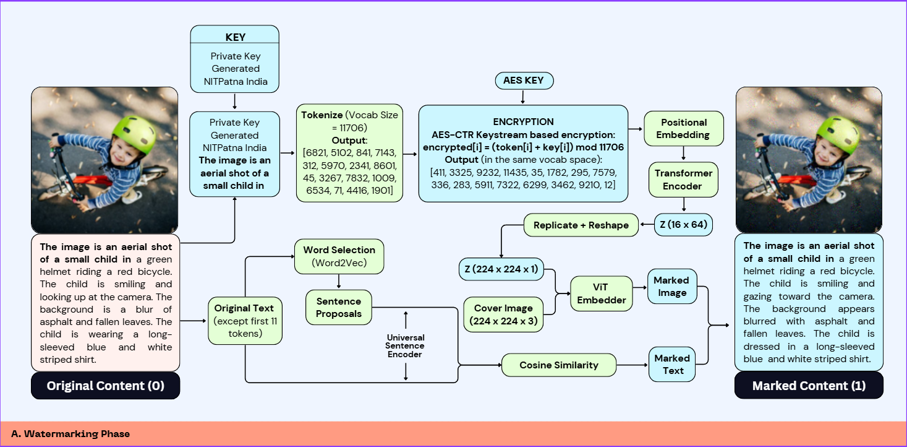

### 16 token Text -> Encoder -> WordEmbedding + Noise -> Decoder -> 16 token Text

#### Here, 16 tokens = Key(5 tokens) + Text(11 tokens)

### Steps performed:
#### 1. train, val, and test data
#### 2. Vocabulary from training dataset (word->id)
#### 3. Load KEY from Key.txt and prepend to every sequence
#### 4. Training + Evaluation

In [ ]:
from datasets import load_from_disk

dataset = load_from_disk("/content/drive/MyDrive/MediaMark/my_dataset")

Loading dataset from disk:   0%|          | 0/38 [00:00<?, ?it/s]

In [ ]:
print(dataset)
print(dataset.column_names)
print(len(dataset['file_name']))

Dataset({
    features: ['file_name', 'text', 'image', 'image_transformed'],
    num_rows: 19610
})
['file_name', 'text', 'image', 'image_transformed']
19610


In [ ]:
dataset.set_format(type=None) # Now it is containing normal text, and image datas, not pytorch type for image_transformed

In [ ]:
# Step 1: 70% train, 30% temp
split_1 = dataset.train_test_split(test_size=0.3, seed=42)
# Step 2: 15% val, 15% test (split the 30%)
split_2 = split_1["test"].train_test_split(test_size=0.5, seed=42)

train_data = split_1["train"]
val_data = split_2["train"]
test_data = split_2["test"]

In [ ]:
# train_data = train_data.select_columns(["text"])
# val_data = val_data.select_columns(["text"])
# test_data = test_data.select_columns(["text"])
train_data = train_data["text"]
val_data = val_data["text"]
test_data = test_data["text"]

In [ ]:
print(len(train_data))
print(len(val_data))
print(len(test_data))

13727
2941
2942


In [ ]:
print('Train Data:       ', train_data[0])
print('Validation Data:  ', val_data[0])
print('Testing Data:     ', test_data[0])

Train Data:        The image captures three Afro-Colombian women wearing traditional dresses and carrying large trays of tropical fruits on their heads. They are standing in front of a colorful colonial building with onlookers in the background. The women are dressed in bright colors, with the woman in the middle wearing a yellow blouse and a red and blue skirt, the woman to the left wearing a green blouse and a yellow skirt, and the woman to the right wearing a red blouse and a green skirt. They are all smiling and appear to be happy. The background of the image is blurred, but it appears to be a street in a Latin American city.
Validation Data:   The image captures a picturesque mountain landscape, featuring a man and a woman standing on a rocky outcrop. They are dressed in hiking gear, with backpacks and trekking poles, and appear to be enjoying the scenic view. The man is wearing a blue shirt and black pants, while the woman is wearing a red shirt and black pants. The background of

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import re
import math
import random
import os
from collections import Counter


In [ ]:
# ══════════════════════════════════════════════════════════════════
# AES-CTR TOKEN-SPACE ENCRYPTION
# Pipeline:
#   Original Token IDs (16)
#     ↓  encrypted[i] = (token[i] + key[i]) mod VOCAB_SIZE
#   Encrypted Token IDs (16)  — fed into the model unchanged
#     ↓  [model pipeline — UNCHANGED]
#   Extracted Encrypted Token IDs (16)
#     ↓  recovered[i] = (extracted[i] - key[i] + VOCAB_SIZE) mod VOCAB_SIZE
#   Recovered Token IDs (16)  ✓
#
#   AES_KEY travels separately (shared secret between sender/receiver).
# ══════════════════════════════════════════════════════════════════
SEQ_LEN = 16

import os, struct
try:
    from Crypto.Cipher import AES
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "pycryptodome", "-q"])
    from Crypto.Cipher import AES


def get_key_tokens(aes_key: bytes, vocab_size: int, seq_len: int = SEQ_LEN) -> list:
    """
    Expand AES-128 key into seq_len key-token values in [0, vocab_size-1]
    using AES-CTR keystream.  2 bytes of keystream consumed per position.
    vocab_size is always passed dynamically as len(vocab.word2idx).
    """
    cipher    = AES.new(aes_key, AES.MODE_CTR, nonce=b'\x00' * 8)
    keystream = cipher.encrypt(b'\x00' * (seq_len * 2))
    return [
        struct.unpack('>H', keystream[i * 2 : i * 2 + 2])[0] % vocab_size
        for i in range(seq_len)
    ]


def encrypt_tokens(token_ids, aes_key: bytes, vocab_size: int) -> list:
    """encrypted[i] = (token[i] + key[i]) mod vocab_size"""
    if hasattr(token_ids, 'tolist'):
        token_ids = token_ids.tolist()
    keys = get_key_tokens(aes_key, vocab_size, len(token_ids))
    return [(t + k) % vocab_size for t, k in zip(token_ids, keys)]


def decrypt_tokens(token_ids, aes_key: bytes, vocab_size: int) -> list:
    """recovered[i] = (extracted[i] - key[i] + vocab_size) mod vocab_size"""
    if hasattr(token_ids, 'tolist'):
        token_ids = token_ids.tolist()
    keys = get_key_tokens(aes_key, vocab_size, len(token_ids))
    return [(t - k + vocab_size) % vocab_size for t, k in zip(token_ids, keys)]


print("AES-CTR token-encryption helpers loaded.")


AES-CTR token-encryption helpers loaded.


In [ ]:
# Constants

SEQ_LEN = 16
KEY_TOKENS_COUNT = 5           # prefix loaded from KEY.txt
TEXT_TOKENS_COUNT = SEQ_LEN - KEY_TOKENS_COUNT   # 11 text tokens

EMBED_DIM = 64
FF_DIM = 512
NUM_HEADS = 4
NUM_ENC_LAYERS = 3
NUM_DEC_LAYERS = 3
DROPOUT = 0.1
NOISE_STRENGTH = 0.8
NOISE_ZERO_FRAC = 0.3
GAUSSIAN_STD = 2.0
GAUSSIAN_BLUR_K = 3
PRETRAIN_EPOCHS = 300
BATCH_SIZE = 128 # 32
REPEAT_TIMES = 49

LR_PRETRAIN = 1e-4

PATH = "/content/drive/MyDrive/MediaMark/Modals/"
KEY_PATH = "/content/drive/MyDrive/MediaMark/Key/KEY.txt"
AES_KEY_PATH = "/content/drive/MyDrive/MediaMark/Key/AES_KEY.bin"

PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"
BOS_TOKEN = "<BOS>"
EOS_TOKEN = "<EOS>"

SPECIAL_TOKENS = [PAD_TOKEN, UNK_TOKEN, BOS_TOKEN, EOS_TOKEN]
PAD_IDX, UNK_IDX, BOS_IDX, EOS_IDX = 0, 1, 2, 3
# PAD (0) → Padding (fills shorter sentences)
# UNK (1) → Unknown word (not in vocab)
# BOS (2) → Beginning of sentence
# EOS (3) → End of sentence

NOISE_TYPES = ["zero_masking", "gaussian_blur", "gaussian_random"]

# Vocabulary class
class Vocabulary:
    ''' Builds word<->index mapping
        Words are first lowercased and split on non-alphabetic characters.
    '''
    def __init__(self, min_freq: int = 1):
        self.min_freq = min_freq
        self.word2idx = {}
        self.idx2word = {}
        self._add_specials()

    def _add_specials(self):
        for tok in SPECIAL_TOKENS:
            idx = len(self.word2idx)
            self.word2idx[tok] = idx
            self.idx2word[idx] = tok

    @staticmethod
    def tokenize(sentence: str):
        return re.findall(r"[a-zA-Z']+", sentence.lower())

    def build(self, sentences):
        counter = Counter()
        for s in sentences:
            counter.update(self.tokenize(s))
        for word, freq in counter.items():
            if freq>=self.min_freq and word not in self.word2idx:
                idx = len(self.word2idx)
                self.word2idx[word] = idx
                self.idx2word[idx] = word
        return self

    def encode(self, sentence: str, seq_len: int = SEQ_LEN) -> torch.Tensor:
        tokens = self.tokenize(sentence)[:seq_len]
        ids  = [self.word2idx.get(t, UNK_IDX) for t in tokens]
        ids += [PAD_IDX] * (seq_len - len(ids))
        return torch.tensor(ids, dtype=torch.long)


    def decode(self, ids) -> str:
        words = []
        for i in ids:
            i = int(i)
            word = self.idx2word.get(i, UNK_TOKEN)
            if word == PAD_TOKEN:
                break
            words.append(word)
        return " ".join(words)

    def __len__(self):
        return len(self.word2idx)

def load_key_tokens(path: str) -> list:
    """
    Read KEY.txt (single line, e.g. '"Private Key Generated NITPatna India"')
    and tokenize into exactly KEY_TOKENS_COUNT words.
    """
    with open(path, "r") as f:
        raw = f.read().strip()
    tokens = Vocabulary.tokenize(raw)
    if len(tokens) != KEY_TOKENS_COUNT:
        raise ValueError(
            f"KEY.txt must tokenize to exactly {KEY_TOKENS_COUNT} tokens, "
            f"got {len(tokens)}: {tokens}"
        )
    return tokens

def add_key_tokens_to_vocab(vocab: Vocabulary, key_tokens: list) -> None:
    """
    Guarantee every key token has a proper vocab entry (never maps to UNK).
    Call AFTER vocab.build() so key tokens sit at the high end of the index space
    and don't interfere with normal words.
    """
    for tok in key_tokens:
        if tok not in vocab.word2idx:
            idx = len(vocab.word2idx)
            vocab.word2idx[tok] = idx
            vocab.idx2word[idx] = tok

class SentenceDataset(Dataset):
    """
    Each sample is a length-SEQ_LEN (16) tensor:
        [ key_id_0, key_id_1, key_id_2, key_id_3, key_id_4,   ← 5 key tokens
          text_0, text_1, …, text_10 ]                          ← 11 text tokens

    Pass key_tokens=None to fall back to the original 16-token-from-text behaviour.
    """
    def __init__(
        self,
        sentences,
        vocab: Vocabulary,
        seq_len: int = SEQ_LEN,
        key_tokens: list = None,
        aes_key=None,
        vocab_size=None
    ):
        self.sentences = sentences
        self.vocab     = vocab
        self.seq_len   = seq_len
        self.aes_key    = aes_key
        self.vocab_size = vocab_size if vocab_size is not None else len(vocab.word2idx)

        # pre-compute key IDs once; they are the same for every sample
        if key_tokens:
            self.key_ids  = [vocab.word2idx[t] for t in key_tokens]
            self.text_len = seq_len - len(self.key_ids)   # 11
        else:
            self.key_ids  = []
            self.text_len = seq_len  # 16


    def __len__(self):
        return len(self.sentences)

    def __getitem__(self, idx) -> torch.Tensor:
        # take only self.text_len (11) tokens from the sentence
        tokens   = self.vocab.tokenize(self.sentences[idx])[: self.text_len]
        text_ids = [self.vocab.word2idx.get(t, UNK_IDX) for t in tokens]
        text_ids += [PAD_IDX] * (self.text_len - len(text_ids))   # pad to 11

        src = torch.tensor(self.key_ids + text_ids, dtype=torch.long)  # (SEQ_LEN=16,)

        # ── AES-CTR token-space encryption (if key provided) ──
        if self.aes_key is not None:
            enc_ids = encrypt_tokens(src.tolist(), self.aes_key, self.vocab_size)
            src = torch.tensor(enc_ids, dtype=torch.long)

        return src
        # return torch.tensor(self.key_ids + text_ids, dtype=torch.long)


class PositionEncoding(nn.Module):
    def __init__(self, d_model: int, max_len: int = 512, dropout: float = 0.1):
        super().__init__()
        self.dropout = nn.Dropout(p=dropout)
        pe = torch.zeros(max_len, d_model)
        position  = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term  = torch.exp(
            torch.arange(0, d_model, 2, dtype=torch.float) * (-math.log(10000.0) / d_model)
        )
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        x = x + self.pe[:, : x.size(1)]
        return self.dropout(x)

class TextEncoder(nn.Module):
    ''' Token sequence = (BatchSize, 16)
        -> Embedding (BS, 16, 64)
        -> positional encoding
        -> 3*TransformerEncoderLayer (d_model = 64, ff_dim = 512)
        -> Output (Z) = (B, 16, 64) '''
    def __init__(self, vocab_size, embed_dim=EMBED_DIM, num_heads=NUM_HEADS, ff_dim=FF_DIM, num_layers=NUM_ENC_LAYERS, seq_len=SEQ_LEN, dropout=DROPOUT):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_IDX)
        self.pos_enc   = PositionEncoding(embed_dim, max_len=seq_len + 4, dropout=dropout)
        enc_layer = nn.TransformerEncoderLayer(d_model=embed_dim, nhead=num_heads, dim_feedforward=ff_dim, dropout=dropout, batch_first=True)
        # without batch_first: (seq_len, batch_size, d_model), with batch_first: (batch_size, seq_len, d_model) -> It does NOT affect training results
        self.transformer_encoder = nn.TransformerEncoder(enc_layer, num_layers=num_layers)

    def forward(self, src, src_key_padding_mask=None):
        x = self.pos_enc(self.embedding(src))
        return self.transformer_encoder(x, src_key_padding_mask=src_key_padding_mask)

class TextDecoder(nn.Module):
    ''' Z (B, 16, 64) + target tokens(B, 16)
        -> 3 * TransformerDecoderLayer (d_model = 64, ff_dim = 512)
        -> Fully Connected head = logits (B, 16, vocab_size)
    '''
    def __init__(self, vocab_size, embed_dim=EMBED_DIM, num_heads=NUM_HEADS, ff_dim=FF_DIM, num_layers=NUM_DEC_LAYERS, seq_len=SEQ_LEN, dropout=DROPOUT):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_IDX)
        self.pos_enc   = PositionEncoding(embed_dim, max_len=seq_len + 4, dropout=dropout)
        dec_layer = nn.TransformerDecoderLayer(d_model=embed_dim, nhead=num_heads, dim_feedforward=ff_dim, dropout=dropout, batch_first=True)
        self.transformer_decoder = nn.TransformerDecoder(dec_layer, num_layers=num_layers)
        self.fc_out = nn.Linear(embed_dim, vocab_size)
    @staticmethod
    def _causal_mask(size, device): #cause-effect relationship
        # torch.triu -> keeps the upper triangular part only
        # True = block (don’t allow attention), False = allow attention
        return torch.triu(torch.ones(size, size, device=device),diagonal=1).bool()

    def forward(self, tgt, memory, tgt_key_padding_mask=None):
        T = tgt.size(1)
        tgt_mask = self._causal_mask(T, tgt.device)
        x = self.pos_enc(self.embedding(tgt))
        out = self.transformer_decoder(x, memory, tgt_mask=tgt_mask, tgt_key_padding_mask=tgt_key_padding_mask)
        return self.fc_out(out) # (B, 16, vocab_size)


### Testing How Encryption is working
In conclusion, during the loss function, we have to first decrypt the tokens before comparing them.

In [ ]:
# Loading Dataset
train_data = [line.strip().lower() for line in train_data]
val_data = [line.strip().lower() for line in val_data]
test_data = [line.strip().lower() for line in test_data]

# Building Vocabulary from training sentences
vocab = Vocabulary(min_freq=1).build(train_data)
key_tokens = load_key_tokens(KEY_PATH)
add_key_tokens_to_vocab(vocab, key_tokens)
key_ids = [vocab.word2idx[t] for t in key_tokens]

VOCAB_SIZE = len(vocab)

print(f"Key tokens        : {key_tokens}")
print(f"Key IDs           : {key_ids}")
print(f"Vocabulary size   : {VOCAB_SIZE}  (after key injection)")
print(f"Train sentences   : {len(train_data)}")
print(f"Val sentences     : {len(val_data)}")
print(f"Test sentences    : {len(test_data)}")
print(f"Tokens per sample : {KEY_TOKENS_COUNT} key + {TEXT_TOKENS_COUNT} text = {SEQ_LEN}")
print()


# ── AES-CTR token encryption setup ──────────────────────────────────────
print(f"AES-CTR encryption enabled | vocab_size={VOCAB_SIZE} (dynamic)")
# 128-bit shared secret
if os.path.exists(AES_KEY_PATH):
    with open(AES_KEY_PATH, "rb") as f:
        AES_KEY = f.read()
else:
    AES_KEY = os.urandom(16)   # 128-bit key
    with open(AES_KEY_PATH, "wb") as f:
        f.write(AES_KEY)
print(f"AES_KEY: {AES_KEY}\n")

# Datasets and loaders
train_ds = SentenceDataset(train_data, vocab, key_tokens=key_tokens, aes_key=AES_KEY, vocab_size=VOCAB_SIZE)
val_ds   = SentenceDataset(val_data,   vocab, key_tokens=key_tokens, aes_key=AES_KEY, vocab_size=VOCAB_SIZE)
test_ds  = SentenceDataset(test_data,  vocab, key_tokens=key_tokens, aes_key=AES_KEY, vocab_size=VOCAB_SIZE)


train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)



Key tokens        : ['private', 'key', 'generated', 'nitpatna', 'india']
Key IDs           : [6410, 5964, 9149, 11704, 2053]
Vocabulary size   : 11705  (after key injection)
Train sentences   : 13727
Val sentences     : 2941
Test sentences    : 2942
Tokens per sample : 5 key + 11 text = 16

AES-CTR encryption enabled | vocab_size=11705 (dynamic)
AES_KEY: b'\x8bQ\xdb\xdb\xe6.\xad\xf1]\x0e\xfb\x98\xbf/\xf2&'



In [ ]:
sample = next(iter(train_loader))

In [ ]:
print(sample)

tensor([[ 1024,  9665,  4036,  ...,  8145,  6669,  6254],
        [ 1024,  9665,  4036,  ...,  9735,  6777,  6435],
        [ 1024,  9665,  4036,  ...,  8217,  6584,  7436],
        ...,
        [ 1024,  9665,  4036,  ..., 10722,  6653,  6427],
        [ 1024,  9665,  4036,  ...,  8226,  6599,  7090],
        [ 1024,  9665,  4036,  ...,  8910,  7922,  7124]])


In [ ]:
sample_text = "image is an aerial shot of a small child in a green helmet riding a red bicycle. The child is smiling and looking up at the camera. The background is a blur of asphalt and fallen leaves. The child is wearing a long-sleeved blue and white striped shirt."

In [ ]:
sample_ds = SentenceDataset(
    sentences=[sample_text],
    vocab=vocab,
    key_tokens=key_tokens,
    aes_key=AES_KEY,
    vocab_size=VOCAB_SIZE
)

sample_loader = DataLoader(sample_ds, batch_size=1, shuffle=False)

In [ ]:
for batch in sample_loader:
    # batch shape: [1, 16]
    enc_ids = batch[0]  # shape: [16]

    # 1) decrypt token ids
    dec_ids = decrypt_tokens(enc_ids, AES_KEY, VOCAB_SIZE)

    # 2) split key prefix and text part
    recovered_key_ids  = dec_ids[:KEY_TOKENS_COUNT]
    recovered_text_ids = dec_ids[KEY_TOKENS_COUNT:]

    # 3) convert text token ids back to words
    recovered_key = vocab.decode(recovered_key_ids)
    recovered_sentence = vocab.decode(recovered_text_ids)

    print("Encrypted ids :", enc_ids.tolist())
    print("Decrypted ids  :", dec_ids)
    print("Key ids        :", recovered_key_ids)
    print("Text ids       :", recovered_text_ids)
    print("Recovered key  :", recovered_key)
    print("Recovered text :", recovered_sentence)

Encrypted ids : [1024, 9665, 4036, 6576, 381, 2093, 5378, 6001, 6855, 4259, 8829, 1131, 3058, 9559, 6597, 6256]
Decrypted ids  : [6410, 5964, 9149, 11704, 2053, 5, 55, 620, 621, 1343, 18, 29, 612, 1443, 27, 29]
Key ids        : [6410, 5964, 9149, 11704, 2053]
Text ids       : [5, 55, 620, 621, 1343, 18, 29, 612, 1443, 27, 29]
Recovered key  : private key generated nitpatna india
Recovered text : image is an aerial shot of a small child in a


### Testing Ended

In [ ]:
class SentenceReconstructionLoss(nn.Module):
    ''' Binary cross entropy: L1 = -sum x_i * log(x'_i) '''
    def __init__(self):
        super().__init__()
        self.ce = nn.CrossEntropyLoss(ignore_index=PAD_IDX)

    def forward(self, logits, targets):
        B, T, V = logits.shape
        return self.ce(logits.reshape(B*T, V), targets.reshape(B*T))

def repeat_text_embedding(z, times = REPEAT_TIMES):
    return z.unsqueeze(1).expand(-1, times, -1, -1)

def _gaussian_kernel_1d(kernel_size, sigma=1.0):
    ''' mean = 0 and standard deviation = sigma for vector '''
    coords = torch.arange(kernel_size, dtype=torch.float) - kernel_size // 2
    k = torch.exp(-0.5 * (coords/sigma) ** 2)
    return k/k.sum()

def noise_zero_masking(z, frac=NOISE_ZERO_FRAC):
    ''' randomly sets some values of tensor z to zero '''
    return z*(torch.rand_like(z) > frac).float()

def noise_gaussian_blur_1d(z, kernel_size=GAUSSIAN_BLUR_K):
    B, T, D = z.shape
    k = _gaussian_kernel_1d(kernel_size).to(z.device)
    k = k.view(1,1,-1).expand(D, 1, -1)
    blurred = F.conv1d(z.permute(0,2,1),k, padding=kernel_size // 2, groups=D)
    return blurred.permute(0,2,1)

def noise_gaussian_random(z, mean=0.0, std=GAUSSIAN_STD):
    return z + torch.randn_like(z)*std + mean

def apply_random_noise(z, strength=NOISE_STRENGTH):
    chosen = random.choice(NOISE_TYPES)
    noisy = {"zero_masking": noise_zero_masking,
            "gaussian_blur": noise_gaussian_blur_1d,
            "gaussian_random": noise_gaussian_random}[chosen](z)
    return (1.0 - strength)*z + strength*noisy

class TextAutoEncoder(nn.Module):
    def __init__(self, vocab_size, **kwargs):
        super().__init__()
        self.encoder = TextEncoder(vocab_size, **kwargs)
        self.decoder = TextDecoder(vocab_size, **kwargs)

    def forward(self, src, tgt, add_noise=False):
        z = self.encoder(src)
        if add_noise:
            z = apply_random_noise(z)
        return self.decoder(tgt, z)

    def encode(self, src):
        return self.encoder(src)

def decrypt_batch(x, aes_key, vocab_size, device):
    """
    x: [B, T] encrypted token ids
    returns: [B, T] decrypted token ids
    """
    if isinstance(x, torch.Tensor):
        x = x.detach().cpu().tolist()
    out = [decrypt_tokens(row, aes_key, vocab_size) for row in x]
    return torch.tensor(out, dtype=torch.long, device=device)

def pretrain(model, train_loader, val_loader, epochs=PRETRAIN_EPOCHS, lr=LR_PRETRAIN,
             device="cuda" if torch.cuda.is_available() else "cpu"):
    model = model.to(device)
    optimiser = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = SentenceReconstructionLoss().to(device)
    history = {"train_loss": [], "val_loss": []}

    for epoch in range(1, epochs + 1):
        model.train()
        train_loss = 0.0

        for src_enc in train_loader:
            src_enc = src_enc.to(device)  # encrypted [B, 16]

            # plaintext targets
            src_plain = decrypt_batch(src_enc, AES_KEY, VOCAB_SIZE, device)

            bos = torch.full((src_enc.size(0), 1), BOS_IDX, dtype=torch.long, device=device)
            tgt_in = torch.cat([bos, src_plain[:, :-1]], dim=1)
            tgt_out = src_plain

            optimiser.zero_grad(set_to_none=True)
            logits = model(src_enc, tgt_in, add_noise=True)
            loss = criterion(logits, tgt_out)
            loss.backward()
            optimiser.step()

            train_loss += loss.item()

        train_loss /= len(train_loader)

        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for src_enc in val_loader:
                src_enc = src_enc.to(device)
                src_plain = decrypt_batch(src_enc, AES_KEY, VOCAB_SIZE, device)

                bos = torch.full((src_enc.size(0), 1), BOS_IDX, dtype=torch.long, device=device)
                tgt_in = torch.cat([bos, src_plain[:, :-1]], dim=1)
                tgt_out = src_plain

                logits = model(src_enc, tgt_in, add_noise=False)
                val_loss += criterion(logits, tgt_out).item()

        val_loss /= len(val_loader)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        if epoch % 50 == 0 or epoch == 1:
            print(f"Epoch {epoch:4d}/{epochs}  | Train Loss: {train_loss:.4f}  | Val Loss: {val_loss:.4f}")

    return history


def compute_bleu(model, data_loader, device):
    model.eval()
    token_correct, token_total = 0, 0
    exact_correct, exact_total = 0, 0

    with torch.no_grad():
        for src_enc in data_loader:
            src_enc = src_enc.to(device)
            src_plain = decrypt_batch(src_enc, AES_KEY, VOCAB_SIZE, device)

            B, T = src_plain.shape
            z = model.encode(src_enc)

            decoded = torch.full((B, 1), BOS_IDX, dtype=torch.long, device=device)

            for _ in range(T):
                pad_len = T - decoded.size(1)
                dec_input = torch.cat(
                    [decoded, torch.full((B, pad_len), PAD_IDX, dtype=torch.long, device=device)],
                    dim=1
                )

                logits = model.decoder(dec_input, z)
                next_tok = logits[:, decoded.size(1) - 1].argmax(-1, keepdim=True)
                decoded = torch.cat([decoded, next_tok], dim=1)

            pred_ids = decoded[:, 1:]  # remove BOS

            token_correct += (pred_ids == src_plain).sum().item()
            token_total += src_plain.numel()

            exact_correct += (pred_ids == src_plain).all(dim=1).sum().item()
            exact_total += B

    token_acc = 100.0 * token_correct / token_total
    exact_acc = 100.0 * exact_correct / exact_total

    print(f"Token accuracy: {token_acc:.2f}%")
    print(f"Exact sequence accuracy: {exact_acc:.2f}%")
    return token_acc

In [ ]:
if __name__ == "__main__":
    # Loading Dataset
    train_data = [line.strip().lower() for line in train_data]
    val_data = [line.strip().lower() for line in val_data]
    test_data = [line.strip().lower() for line in test_data]

    # Building Vocabulary from training sentences
    vocab = Vocabulary(min_freq=1).build(train_data)
    key_tokens = load_key_tokens(KEY_PATH)
    add_key_tokens_to_vocab(vocab, key_tokens)
    key_ids = [vocab.word2idx[t] for t in key_tokens]

    VOCAB_SIZE = len(vocab)

    print(f"Key tokens        : {key_tokens}")
    print(f"Key IDs           : {key_ids}")
    print(f"Vocabulary size   : {VOCAB_SIZE}  (after key injection)")
    print(f"Train sentences   : {len(train_data)}")
    print(f"Val sentences     : {len(val_data)}")
    print(f"Test sentences    : {len(test_data)}")
    print(f"Tokens per sample : {KEY_TOKENS_COUNT} key + {TEXT_TOKENS_COUNT} text = {SEQ_LEN}")
    print()


    # ── AES-CTR token encryption setup ──────────────────────────────────────
    print(f"AES-CTR encryption enabled | vocab_size={VOCAB_SIZE} (dynamic)")
    # 128-bit shared secret
    if os.path.exists(AES_KEY_PATH):
        with open(AES_KEY_PATH, "rb") as f:
            AES_KEY = f.read()
    else:
        AES_KEY = os.urandom(16)   # 128-bit key
        with open(AES_KEY_PATH, "wb") as f:
            f.write(AES_KEY)
    print(f"AES_KEY: {AES_KEY}\n")

    # Datasets and loaders
    train_ds = SentenceDataset(train_data, vocab, key_tokens=key_tokens, aes_key=AES_KEY, vocab_size=VOCAB_SIZE)
    val_ds   = SentenceDataset(val_data,   vocab, key_tokens=key_tokens, aes_key=AES_KEY, vocab_size=VOCAB_SIZE)
    test_ds  = SentenceDataset(test_data,  vocab, key_tokens=key_tokens, aes_key=AES_KEY, vocab_size=VOCAB_SIZE)

    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
    val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)


    sample_enc = next(iter(train_loader))
    assert sample_enc.shape == (BATCH_SIZE, SEQ_LEN), \
        f"Expected ({BATCH_SIZE}, {SEQ_LEN}), got {sample_enc.shape}"

    # Verify the first KEY_TOKENS_COUNT positions are always the key
    sample_plain = decrypt_batch(sample_enc, AES_KEY, VOCAB_SIZE, device="cpu")
    assert (sample_plain[:, :KEY_TOKENS_COUNT] ==
            torch.tensor(key_ids).unsqueeze(0)).all(), \
            "Key tokens not recovered correctly!"

    sample_plain = decrypt_batch(sample_enc, AES_KEY, VOCAB_SIZE, device="cpu")

    print(f"Batch shape check passed: {sample_enc.shape}")
    print(f"Encrypted sample[0]: {sample_enc[0].tolist()}")
    print(f"Decrypted sample[0]: {sample_plain[0].tolist()}")
    print(f"Plaintext decoded[0]: {vocab.decode(sample_plain[0])}")
    print()


    # sample = next(iter(train_loader))
    # assert sample.shape == (BATCH_SIZE, SEQ_LEN), \
    #     f"Expected ({BATCH_SIZE}, {SEQ_LEN}), got {sample.shape}"
    # # Verify the first KEY_TOKENS_COUNT positions are always the key
    # assert (sample[:, :KEY_TOKENS_COUNT] ==
    #         torch.tensor(key_ids).unsqueeze(0)).all(), \
    #     "Key tokens not correctly prepended!"
    # print(f"Batch shape check passed: {sample.shape}")
    # print(f"Sample[0] decoded: {vocab.decode(sample[0])}")
    # print()

    # Text Model
    model_16t = TextAutoEncoder(
        vocab_size = VOCAB_SIZE,
        embed_dim  = EMBED_DIM,
        num_heads  = NUM_HEADS,
        ff_dim     = FF_DIM,
        num_layers = NUM_ENC_LAYERS,
        seq_len    = SEQ_LEN,
        dropout    = DROPOUT,
    )
    print(f"Parameters: {sum(p.numel() for p in model_16t.parameters()):,}")

    device = "cuda" if torch.cuda.is_available() else "cpu"
    model_16t = model_16t.to(device)


    dummy_enc = sample_enc.to(device)
    dummy_plain = decrypt_batch(sample_enc, AES_KEY, VOCAB_SIZE, device)

    bos = torch.full((dummy_enc.size(0), 1), BOS_IDX, dtype=torch.long, device=device)
    tgt_in = torch.cat([bos, dummy_plain[:, :-1]], dim=1)

    with torch.no_grad():
        logits = model_16t(dummy_enc, tgt_in, add_noise=True)

    assert logits.shape == (BATCH_SIZE, SEQ_LEN, VOCAB_SIZE)

    # Checking shape of sample encoder-decoder outputs
    # dummy = sample.to(device)
    # bos   = torch.full((dummy.size(0), 1), BOS_IDX, dtype=torch.long, device=device)
    # tgt_in = torch.cat([bos, dummy[:, :-1]], dim=1)
    # with torch.no_grad():
    #     logits = model_16t(dummy, tgt_in, add_noise=True)
    # assert logits.shape == (BATCH_SIZE, SEQ_LEN, VOCAB_SIZE)

    z_enc = model_16t.encode(dummy_enc)
    assert z_enc.shape == (BATCH_SIZE, SEQ_LEN, EMBED_DIM)
    z_rep = repeat_text_embedding(z_enc)
    assert z_rep.shape == (BATCH_SIZE, REPEAT_TIMES, SEQ_LEN, EMBED_DIM)

    print(f"Logits shape  : {logits.shape}")
    print(f"Encoder Z     : {z_enc.shape}")
    print(f"Repeated Z    : {z_rep.shape}")
    print()

    # Training
    print(f"Pre-training on {device} for {PRETRAIN_EPOCHS} epochs …")
    history = pretrain(model_16t, train_loader, val_loader, epochs=PRETRAIN_EPOCHS, lr=LR_PRETRAIN, device=device)

    # Evaluation
    bleu = compute_bleu(model_16t, test_loader, device=device)
    print(f"\nTest token accuracy: {bleu:.2f}%")

    # Save Checkpoints
    os.makedirs(PATH, exist_ok=True)
    torch.save({
        "model_16t_state_dict": model_16t.state_dict(),
        "vocab_word2idx":       vocab.word2idx,
        "vocab_idx2word":       vocab.idx2word,
        "history":              history,
        "bleu":                 bleu,
        "key_tokens":           key_tokens,
        "config": {
            "vocab_size":  VOCAB_SIZE,
            "embed_dim":   EMBED_DIM,
            "num_heads":   NUM_HEADS,
            "ff_dim":      FF_DIM,
            "seq_len":     SEQ_LEN,
        },
    }, PATH + "/16_t_model/model_16t.pt")
    print("Checkpoint saved → model_16t.pt")

Key tokens        : ['private', 'key', 'generated', 'nitpatna', 'india']
Key IDs           : [6410, 5964, 9149, 11704, 2053]
Vocabulary size   : 11705  (after key injection)
Train sentences   : 13727
Val sentences     : 2941
Test sentences    : 2942
Tokens per sample : 5 key + 11 text = 16

AES-CTR encryption enabled | vocab_size=11705 (dynamic)
AES_KEY: b'\x8bQ\xdb\xdb\xe6.\xad\xf1]\x0e\xfb\x98\xbf/\xf2&'

Batch shape check passed: torch.Size([128, 16])
Encrypted sample[0]: [1024, 9665, 4036, 6576, 381, 2092, 5328, 5387, 6263, 3102, 8850, 1129, 2475, 8193, 6811, 6241]
Decrypted sample[0]: [6410, 5964, 9149, 11704, 2053, 4, 5, 6, 29, 186, 39, 27, 29, 77, 241, 14]
Plaintext decoded[0]: private key generated nitpatna india the image captures a young woman in a brown beanie and

Parameters: 2,807,417
Logits shape  : torch.Size([128, 16, 11705])
Encoder Z     : torch.Size([128, 16, 64])
Repeated Z    : torch.Size([128, 49, 16, 64])

Pre-training on cuda for 300 epochs …
Epoch    1/300  | T

In [ ]:
checkpoint = torch.load(PATH + "/16_t_model/model_16t.pt", map_location="cpu")

vocab = Vocabulary()
vocab.word2idx = checkpoint["vocab_word2idx"]
vocab.idx2word = checkpoint["vocab_idx2word"]

key_tokens = checkpoint["key_tokens"]
key_ids = [vocab.word2idx[t] for t in key_tokens]
text_len = SEQ_LEN - len(key_ids)

# Load AES key
with open(AES_KEY_PATH, "rb") as f:
    AES_KEY = f.read()

# ============================================================
# Rebuild model
# ============================================================
model = TextAutoEncoder(
    vocab_size=checkpoint["config"]["vocab_size"],
    embed_dim=checkpoint["config"]["embed_dim"],
    num_heads=checkpoint["config"]["num_heads"],
    ff_dim=checkpoint["config"]["ff_dim"],
    seq_len=checkpoint["config"]["seq_len"],
)

model.load_state_dict(checkpoint["model_16t_state_dict"])
model.eval()

device = "cuda" if torch.cuda.is_available() else "cpu"
model = model.to(device)

# ============================================================
# Input sentence
# ============================================================
sentence = "a man is playing guitar in the woods"

tokens = Vocabulary.tokenize(sentence)[:text_len]

text_ids = [vocab.word2idx.get(t, UNK_IDX) for t in tokens]
text_ids += [PAD_IDX] * (text_len - len(text_ids))

# Plaintext sequence
src_plain = torch.tensor(
    [key_ids + text_ids],
    dtype=torch.long
)

# Encrypt exactly as in SentenceDataset
src_enc = torch.tensor(
    [encrypt_tokens(src_plain[0].tolist(), AES_KEY, len(vocab))],
    dtype=torch.long
).to(device)

# ============================================================
# Forward pass (same pipeline as training)
# ============================================================
with torch.no_grad():

    # Encrypted -> Encoder
    z = model.encode(src_enc)

    # Plaintext decoder input
    bos = torch.full(
        (1, 1),
        BOS_IDX,
        dtype=torch.long,
        device=device
    )

    tgt_in = torch.cat(
        [bos, src_plain[:, :-1].to(device)],
        dim=1
    )

    # Decoder
    logits = model.decoder(tgt_in, z)

    # Predicted plaintext ids
    pred_ids = logits.argmax(dim=-1)

# ============================================================
# Results
# ============================================================
target_ids = src_plain

print("Input sentence:")
print(vocab.decode(target_ids[0][KEY_TOKENS_COUNT:]))

print("\nPredicted sentence:")
print(vocab.decode(pred_ids[0][KEY_TOKENS_COUNT:]))

print("\nTarget IDs:")
print(target_ids[0].tolist())

print("\nPredicted IDs:")
print(pred_ids[0].tolist())

token_acc = (pred_ids.cpu() == target_ids).float().mean().item() * 100
print(f"\nToken accuracy: {token_acc:.2f}%")

Input sentence:
a man is playing guitar in the woods

Predicted sentence:
a man is playing in in the foreground he to to

Target IDs:
[6410, 5964, 9149, 11704, 2053, 29, 65, 55, 945, 2450, 27, 4, 184, 0, 0, 0]

Predicted IDs:
[6410, 5964, 9149, 11704, 2053, 29, 65, 55, 945, 27, 27, 4, 363, 66, 46, 46]

Token accuracy: 68.75%
